# Detección de fraude en tarjetas de crédito

Objetivo: construir un sistema de detección de fraude en tarjetas de crédito usando el dataset etiquetado de construcción.
La idea es intentar que el sistema tenga el mayor AUPR (Área bajo la curva Precision Recall) posible en producción:

from sklearn.metrics import average_precision_score

Se deberá entregar un csv con una única columna con tantas filas como tiene el fichero de producción, y con un score asociado de tal forma que las filas con mayor score sean las que tienen mayor probabilidad de ser fraude.

In [1]:
import sys

COLAB = "google.colab" in sys.modules


In [2]:
import pandas as pd
import numpy as np
from tqdm import tqdm
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score
from sklearn.metrics import average_precision_score

import matplotlib.pyplot as plt
from IPython.display import clear_output

pd.options.display.max_columns = None

# Carga del dataset

In [3]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import is_zipfile

# Jupyter puede arrancar desde la raiz del proyecto o desde notebooks/.
DATA_DIR = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()) / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

if COLAB:
    datasets = {
        "credit_card_construction.csv.zip": "1IyihCpU_krumRnPBvMR0ytEfzv_Z2Jg3",
        "credit_card_production.csv.zip": "1N5xRbkchTR7FLskuIEmZPYHklsRVJy_q",
    }
    for filename, file_id in datasets.items():
        destination = DATA_DIR / filename
        if not destination.is_file():
            url = f"https://drive.usercontent.google.com/download?id={file_id}&export=download&confirm=t"
            temporary = destination.with_suffix(".zip.part")
            urlretrieve(url, temporary)
            if not is_zipfile(temporary):
                temporary.unlink()
                raise ValueError(f"La descarga de {filename} no es un ZIP valido. Revisa el acceso al archivo en Drive.")
            temporary.replace(destination)

print(f"Carpeta de datos: {DATA_DIR.resolve()}")


Carpeta de datos: C:\Users\O013392\Desktop\MIAX\deteccion_outliers_fraude\data


In [4]:
df_const = pd.read_csv(DATA_DIR / "credit_card_construction.csv.zip", compression="zip", low_memory=False)
df_const


Out[4]: 
           X1      X2     X3     X4     X5     X6     X7     X8     X9    X10  \
0       374.0  -288.0 -150.0 -232.0  -90.0  262.0 -262.0   88.0  -26.0  152.0   
1       436.0  -202.0 -566.0 -652.0  166.0   58.0  -18.0   -0.0   54.0  -54.0   
2       388.0  -128.0  -56.0   30.0 -114.0  104.0 -210.0   72.0  298.0    2.0   
3      -486.0     4.0  314.0  -80.0 -276.0  -94.0  -34.0   94.0 -252.0    2.0   
4       258.0  -238.0  300.0  -70.0 -374.0  122.0 -350.0   92.0  134.0   94.0   
...       ...     ...    ...    ...    ...    ...    ...    ...    ...    ...   
170879 -398.0   346.0 -222.0 -534.0  322.0  608.0  -84.0  288.0  190.0  204.0   
170880  -88.0   212.0  316.0   -6.0    8.0 -180.0  146.0  -22.0 -102.0  -66.0   
170881  166.0  -530.0 -632.0   42.0 -112.0 -314.0  322.0 -186.0 -264.0  136.0   
170882 -304.0 -1258.0 -528.0  266.0 -334.0  392.0  272.0   16.0  150.0 -140.0   
170883 -322.0    26.0  416.0 -388.0 -364.0  -86.0   50.0  136.0  236.0 -412.0   

          X11    X

In [5]:
100*df_const["Class"].value_counts()/len(df_const)

Out[5]: 
Class
0    99.827368
1     0.172632
Name: count, dtype: float64


In [6]:
df_const.describe()

Out[6]: 
                  X1             X2             X3             X4  \
count  170884.000000  170884.000000  170884.000000  170884.000000   
mean        0.589499      -0.050923       0.285773      -0.097376   
std       390.920605     330.501997     302.081068     282.572168   
min    -11282.000000  -14544.000000   -6594.000000   -1136.000000   
25%      -184.000000    -120.000000    -178.000000    -170.000000   
50%         4.000000      14.000000      36.000000      -4.000000   
75%       264.000000     162.000000     206.000000     150.000000   
max       490.000000    4294.000000    1876.000000    3344.000000   

                 X5             X6             X7             X8  \
count  170884.00000  170884.000000  170884.000000  170884.000000   
mean        0.28397       0.048828       0.005431       0.217773   
std       270.76069     263.927926     241.111627     238.590168   
min     -6418.00000   -5232.000000   -8302.000000  -14644.000000   
25%      -138.00000    -154.0

In [7]:
df_prod = pd.read_csv(DATA_DIR / "credit_card_production.csv.zip", compression="zip", low_memory=False)
df_prod


Out[7]: 
           X1     X2     X3     X4     X5     X6     X7    X8     X9    X10  \
0       234.0   48.0   58.0  106.0  -30.0  -56.0  -22.0  20.0  -38.0  -30.0   
1       408.0 -126.0 -426.0 -312.0   12.0 -238.0   56.0 -48.0  292.0 -136.0   
2      -150.0   84.0  580.0 -326.0  -86.0 -100.0   74.0 -32.0  494.0 -418.0   
3       296.0 -134.0 -388.0  132.0  -12.0 -228.0  114.0 -70.0   44.0  -88.0   
4      -594.0 -214.0  414.0  308.0   38.0  196.0  -46.0  62.0   70.0   98.0   
...       ...    ...    ...    ...    ...    ...    ...   ...    ...    ...   
113918  392.0  -98.0  -42.0   78.0 -114.0   42.0 -202.0  36.0  490.0  -38.0   
113919  234.0   16.0  -48.0  146.0   36.0   88.0  -64.0  56.0   98.0 -126.0   
113920 -222.0  106.0  430.0 -176.0   74.0  -58.0  152.0 -26.0   34.0 -118.0   
113921  -82.0  380.0 -272.0  182.0  322.0  -46.0  238.0  40.0 -206.0 -176.0   
113922  410.0   26.0 -360.0   44.0  140.0  -56.0   20.0 -16.0   34.0  -46.0   

          X11    X12    X13    X14    X15 

In [8]:
# Matplotlib guarda las figuras como imagenes en el notebook, sin JavaScript.
%matplotlib inline


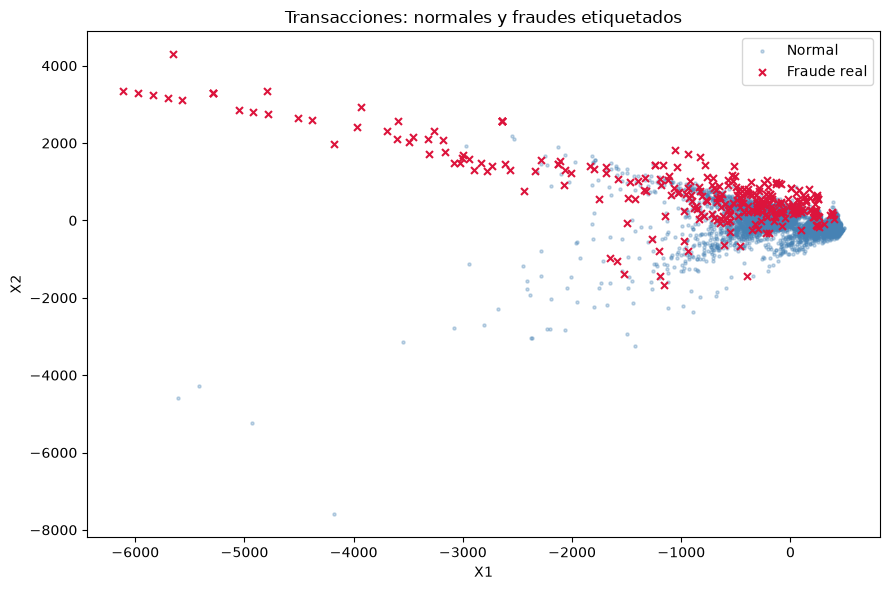

In [9]:
# Muestra reproducible de normales y todos los fraudes para hacerlos visibles.
normales = df_const.loc[df_const["Class"].eq(0)]
fraudes = df_const.loc[df_const["Class"].eq(1)]
muestra = normales.sample(min(10000, len(normales)), random_state=42)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(muestra["X1"], muestra["X2"], s=5, alpha=0.3, label="Normal", color="steelblue")
ax.scatter(fraudes["X1"], fraudes["X2"], s=25, marker="x", label="Fraude real", color="crimson")
ax.set(xlabel="X1", ylabel="X2", title="Transacciones: normales y fraudes etiquetados")
ax.legend()
fig.tight_layout()
plt.show()


In [10]:
df_const.std()

Out[10]: 
X1        390.920605
X2        330.501997
X3        302.081068
X4        282.572168
X5        270.760690
X6        263.927926
X7        241.111627
X8        238.590168
X9        219.366112
X10       216.787580
X11       204.496836
X12       199.591426
X13       198.824463
X14       191.995036
X15       183.039589
X16       175.058560
X17       169.997903
X18       167.325595
X19       162.131421
X20       152.471380
Amount    363.489116
Class       0.041513
dtype: float64


In [11]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(df_const, test_size=0.3, random_state=42, stratify=df_const["Class"])

In [12]:
100*df_const["Class"].value_counts()/len(df_const)

Out[12]: 
Class
0    99.827368
1     0.172632
Name: count, dtype: float64


In [13]:
100*df_train["Class"].value_counts()/len(df_train)

Out[13]: 
Class
0    99.827785
1     0.172215
Name: count, dtype: float64


In [14]:
100*df_test["Class"].value_counts()/len(df_test)

Out[14]: 
Class
0    99.826396
1     0.173604
Name: count, dtype: float64


In [15]:
X_train = df_train.drop("Class", axis=1)
y_train = df_train["Class"]

X_test = df_test.drop("Class", axis=1)
y_test = df_test["Class"]

In [16]:
X_train0 = X_train[y_train==0] # datos ok

In [17]:
X_train0.shape

Out[17]: (119412, 21)


In [18]:
# Construyo modelo estadístico de distribución de datos ok:

from sklearn.mixture import GaussianMixture

gm_model = GaussianMixture(n_components=5, random_state=42)
gm_model.fit(X_train0)

Out[18]: GaussianMixture(n_components=5, random_state=42)


In [19]:
gm_model.score_samples(X_train0) # logaritmo de la probabilidad del punto

Out[19]: 
array([ -99.92017174, -101.45627804, -145.83344619, ..., -106.16757485,
       -159.91221678, -101.78206187], shape=(119412,))


In [20]:
scores_train = gm_model.score_samples(X_train)
pd.DataFrame({"score":scores_train, "y":y_train}).sort_values("score")

Out[20]: 
               score  y
153710 -65102.115504  1
59540  -64199.924183  1
87891  -64199.924183  1
38683  -64199.924183  1
4910   -64021.565425  1
...              ... ..
20265     -95.090705  0
29988     -94.901717  0
17408     -94.879135  0
149845    -94.778473  0
698       -94.689677  0

[119618 rows x 2 columns]


In [21]:
scores_test = gm_model.score_samples(X_test)
pd.DataFrame({"score":scores_test, "y":y_test}).sort_values("score")

Out[21]: 
               score  y
3741   -61266.468379  1
122391 -14819.791565  1
78309  -14819.791565  1
46259   -8183.438510  1
15379   -3189.484447  1
...              ... ..
96365     -95.142326  0
107061    -95.108580  0
161536    -95.012341  0
42655     -94.879135  0
77589     -94.879135  0

[51266 rows x 2 columns]


## Densidad del GMM: curvas de nivel en PCA 2D

Visualizacion con Matplotlib inspirada en el [ejemplo de scikit-learn](https://scikit-learn.org/stable/auto_examples/mixture/plot_gmm_pdf.html). Las curvas muestran `-log p(PC1, PC2)`: valores altos indican menor densidad en la proyeccion.

Se proyectan las medias y covarianzas del GMM entrenado sobre las transacciones normales. Es la distribucion marginal en estas dos componentes, no el score original con todas las variables. Una transaccion anomala puede quedar superpuesta con normales al reducir dimensiones. Las cruces rojas son fraudes **reales** (`Class = 1`), no predicciones del modelo.

La vista completa incluye el rango de todo test; la ampliacion usa los percentiles 1 y 99 de cada eje (con margen) y deja fuera algunos extremos para apreciar las curvas. Los ejes se mantienen en las unidades de la PCA sin escalar del analisis original.

Las salidas anteriores de Plotly solo contenian HTML con JavaScript cargado desde `cdn.plot.ly`. Un visor que bloquee scripts o esa descarga puede mostrarlas en blanco ([renderizadores de Plotly](https://plotly.com/python/renderers/)). Estas figuras se guardan como imagenes al ejecutar el notebook.


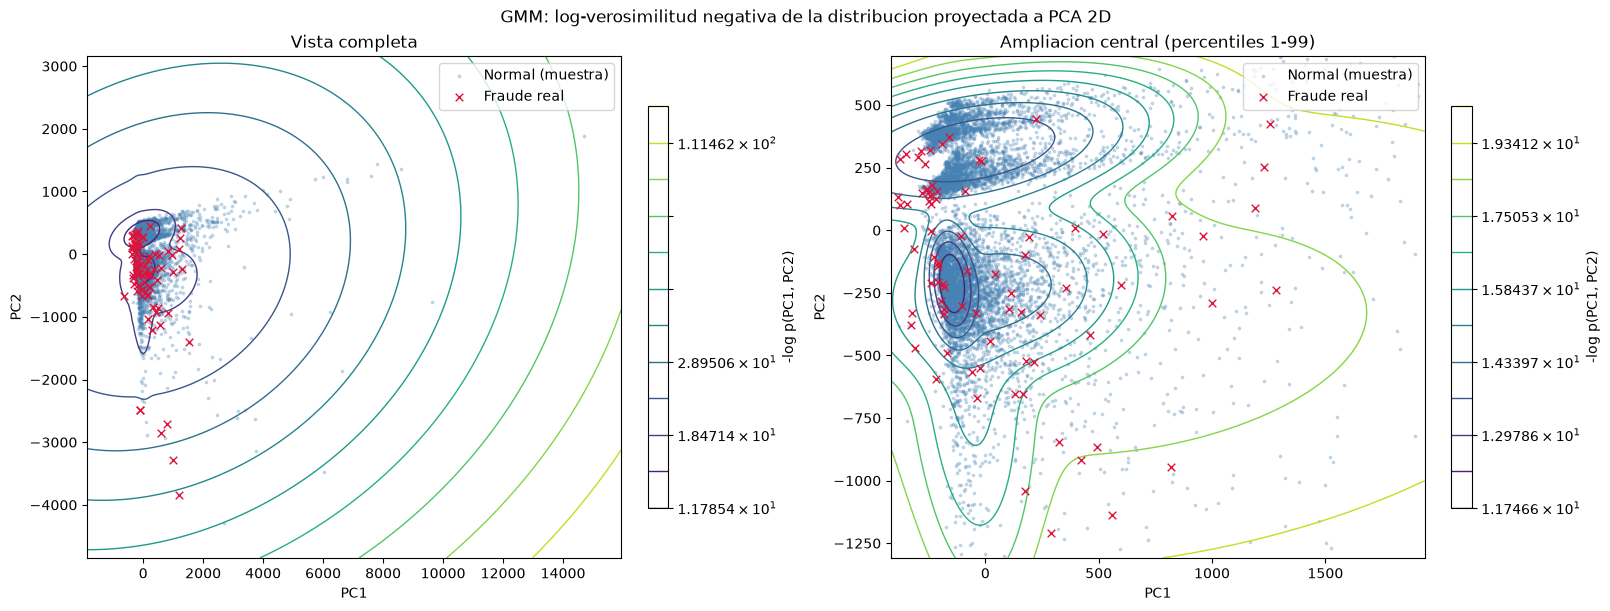

In [22]:
from matplotlib.colors import LogNorm, Normalize
from scipy.special import logsumexp
from scipy.stats import multivariate_normal
from sklearn.decomposition import PCA

# Proyectamos el GMM ya entrenado: cada componente sigue siendo gaussiana.
# No se vuelve a ajustar el modelo ni se modifican scores_train / scores_test.
pca = PCA(n_components=2, random_state=42).fit(X_train0)
Z = pca.transform(X_test)
medias_2d = (gm_model.means_ - pca.mean_) @ pca.components_.T
componentes = pca.components_
covarianzas_2d = np.array([
    componentes @ cov @ componentes.T for cov in gm_model.covariances_
])

def log_densidad_2d(puntos):
    log_componentes = np.column_stack([
        np.log(peso) + multivariate_normal.logpdf(puntos, mean=media, cov=cov)
        for peso, media, cov in zip(gm_model.weights_, medias_2d, covarianzas_2d)
    ])
    return logsumexp(log_componentes, axis=1)

es_fraude = np.asarray(y_test) == 1
indices_normales = np.flatnonzero(~es_fraude)
rng = np.random.default_rng(42)
indices_muestra = rng.choice(indices_normales, min(10000, len(indices_normales)), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), layout="constrained")
for ax, titulo, cuantiles in zip(
    axes, ["Vista completa", "Ampliacion central (percentiles 1-99)"], [(0, 1), (0.01, 0.99)]
):
    limites = np.quantile(Z, cuantiles, axis=0)
    margen = np.maximum(limites[1] - limites[0], 1e-6) * 0.08
    inferior, superior = limites[0] - margen, limites[1] + margen
    x = np.linspace(inferior[0], superior[0], 220)
    y = np.linspace(inferior[1], superior[1], 220)
    xx, yy = np.meshgrid(x, y)
    nll = -log_densidad_2d(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)

    # LogNorm requiere valores positivos; una densidad puede superar 1.
    vmin, vmax = float(nll.min()), float(nll.max())
    if vmin > 0:
        niveles = np.geomspace(vmin, vmax, 12)
        norma = LogNorm(vmin=vmin, vmax=vmax)
    else:
        niveles = np.linspace(vmin, vmax, 12)
        norma = Normalize(vmin=vmin, vmax=vmax)
    curvas = ax.contour(xx, yy, nll, levels=niveles, norm=norma, cmap="viridis", linewidths=1)
    fig.colorbar(curvas, ax=ax, shrink=0.8, label="-log p(PC1, PC2)")
    ax.scatter(Z[indices_muestra, 0], Z[indices_muestra, 1], s=3, alpha=0.25,
               color="steelblue", label="Normal (muestra)")
    ax.scatter(Z[es_fraude, 0], Z[es_fraude, 1], s=30, marker="x",
               color="crimson", linewidths=1, label="Fraude real", zorder=3)
    ax.set(xlim=(inferior[0], superior[0]), ylim=(inferior[1], superior[1]),
           xlabel="PC1", ylabel="PC2", title=titulo)
    ax.legend(loc="upper right")

fig.suptitle("GMM: log-verosimilitud negativa de la distribucion proyectada a PCA 2D")
plt.show()
